In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm
# from preproc_funcs import *
# from generate_plots import *
# from helpers import *
# from preproc_funcs import *
from scipy import stats
import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Loading existing dataframe! If this is not desired, delete the current master_df.csv


In [3]:
df = gm.master_df
oriArrayCols = [col for col in df.columns if col.startswith('oriArray_')]
df['oriSteps'] = df[oriArrayCols].notna().sum(axis=1)
df['abserrorOri'] = np.abs(df['errorOri'])

In [ ]:
df.head()

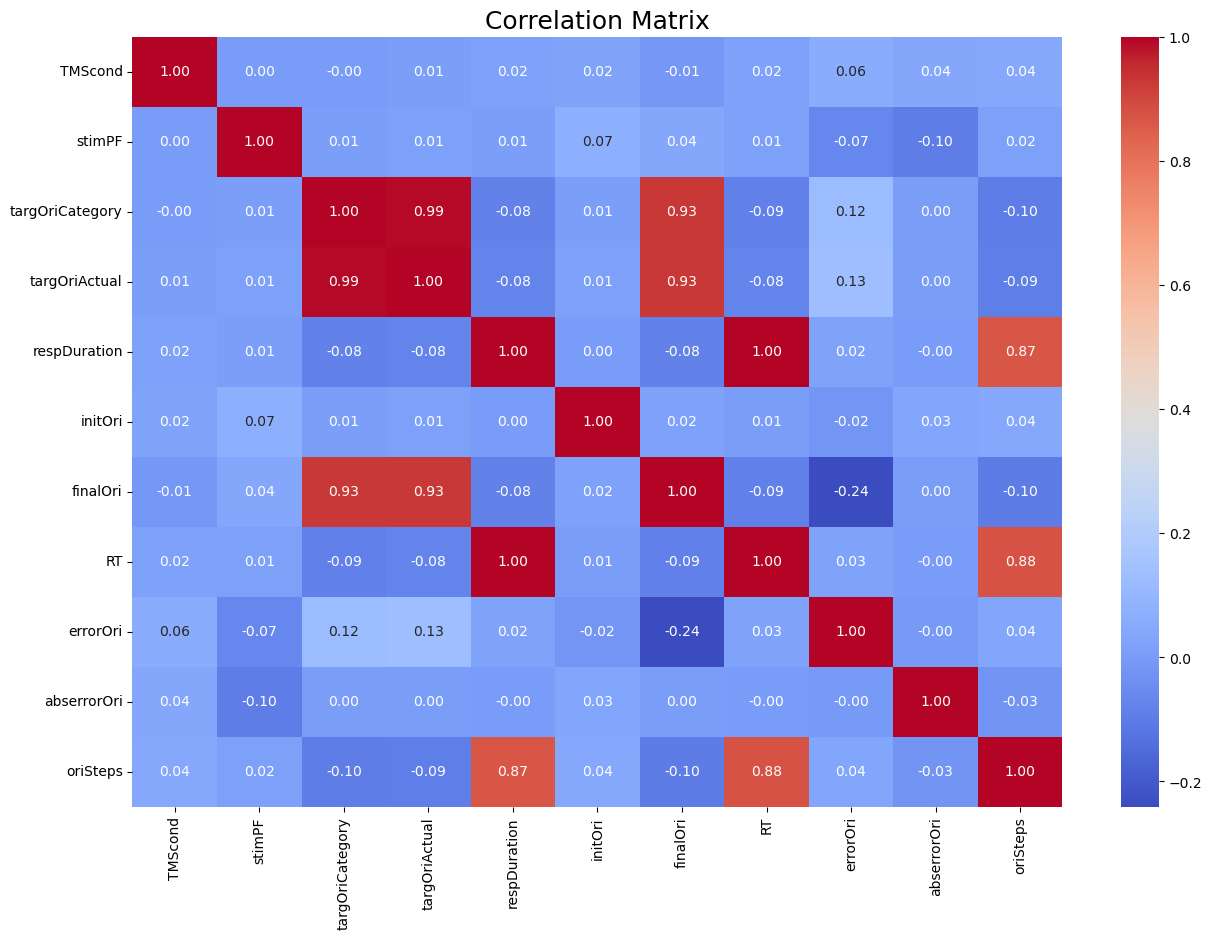

In [4]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'finalOri', 'RT', 'errorOri', 'abserrorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

<Figure size 1500x1000 with 0 Axes>

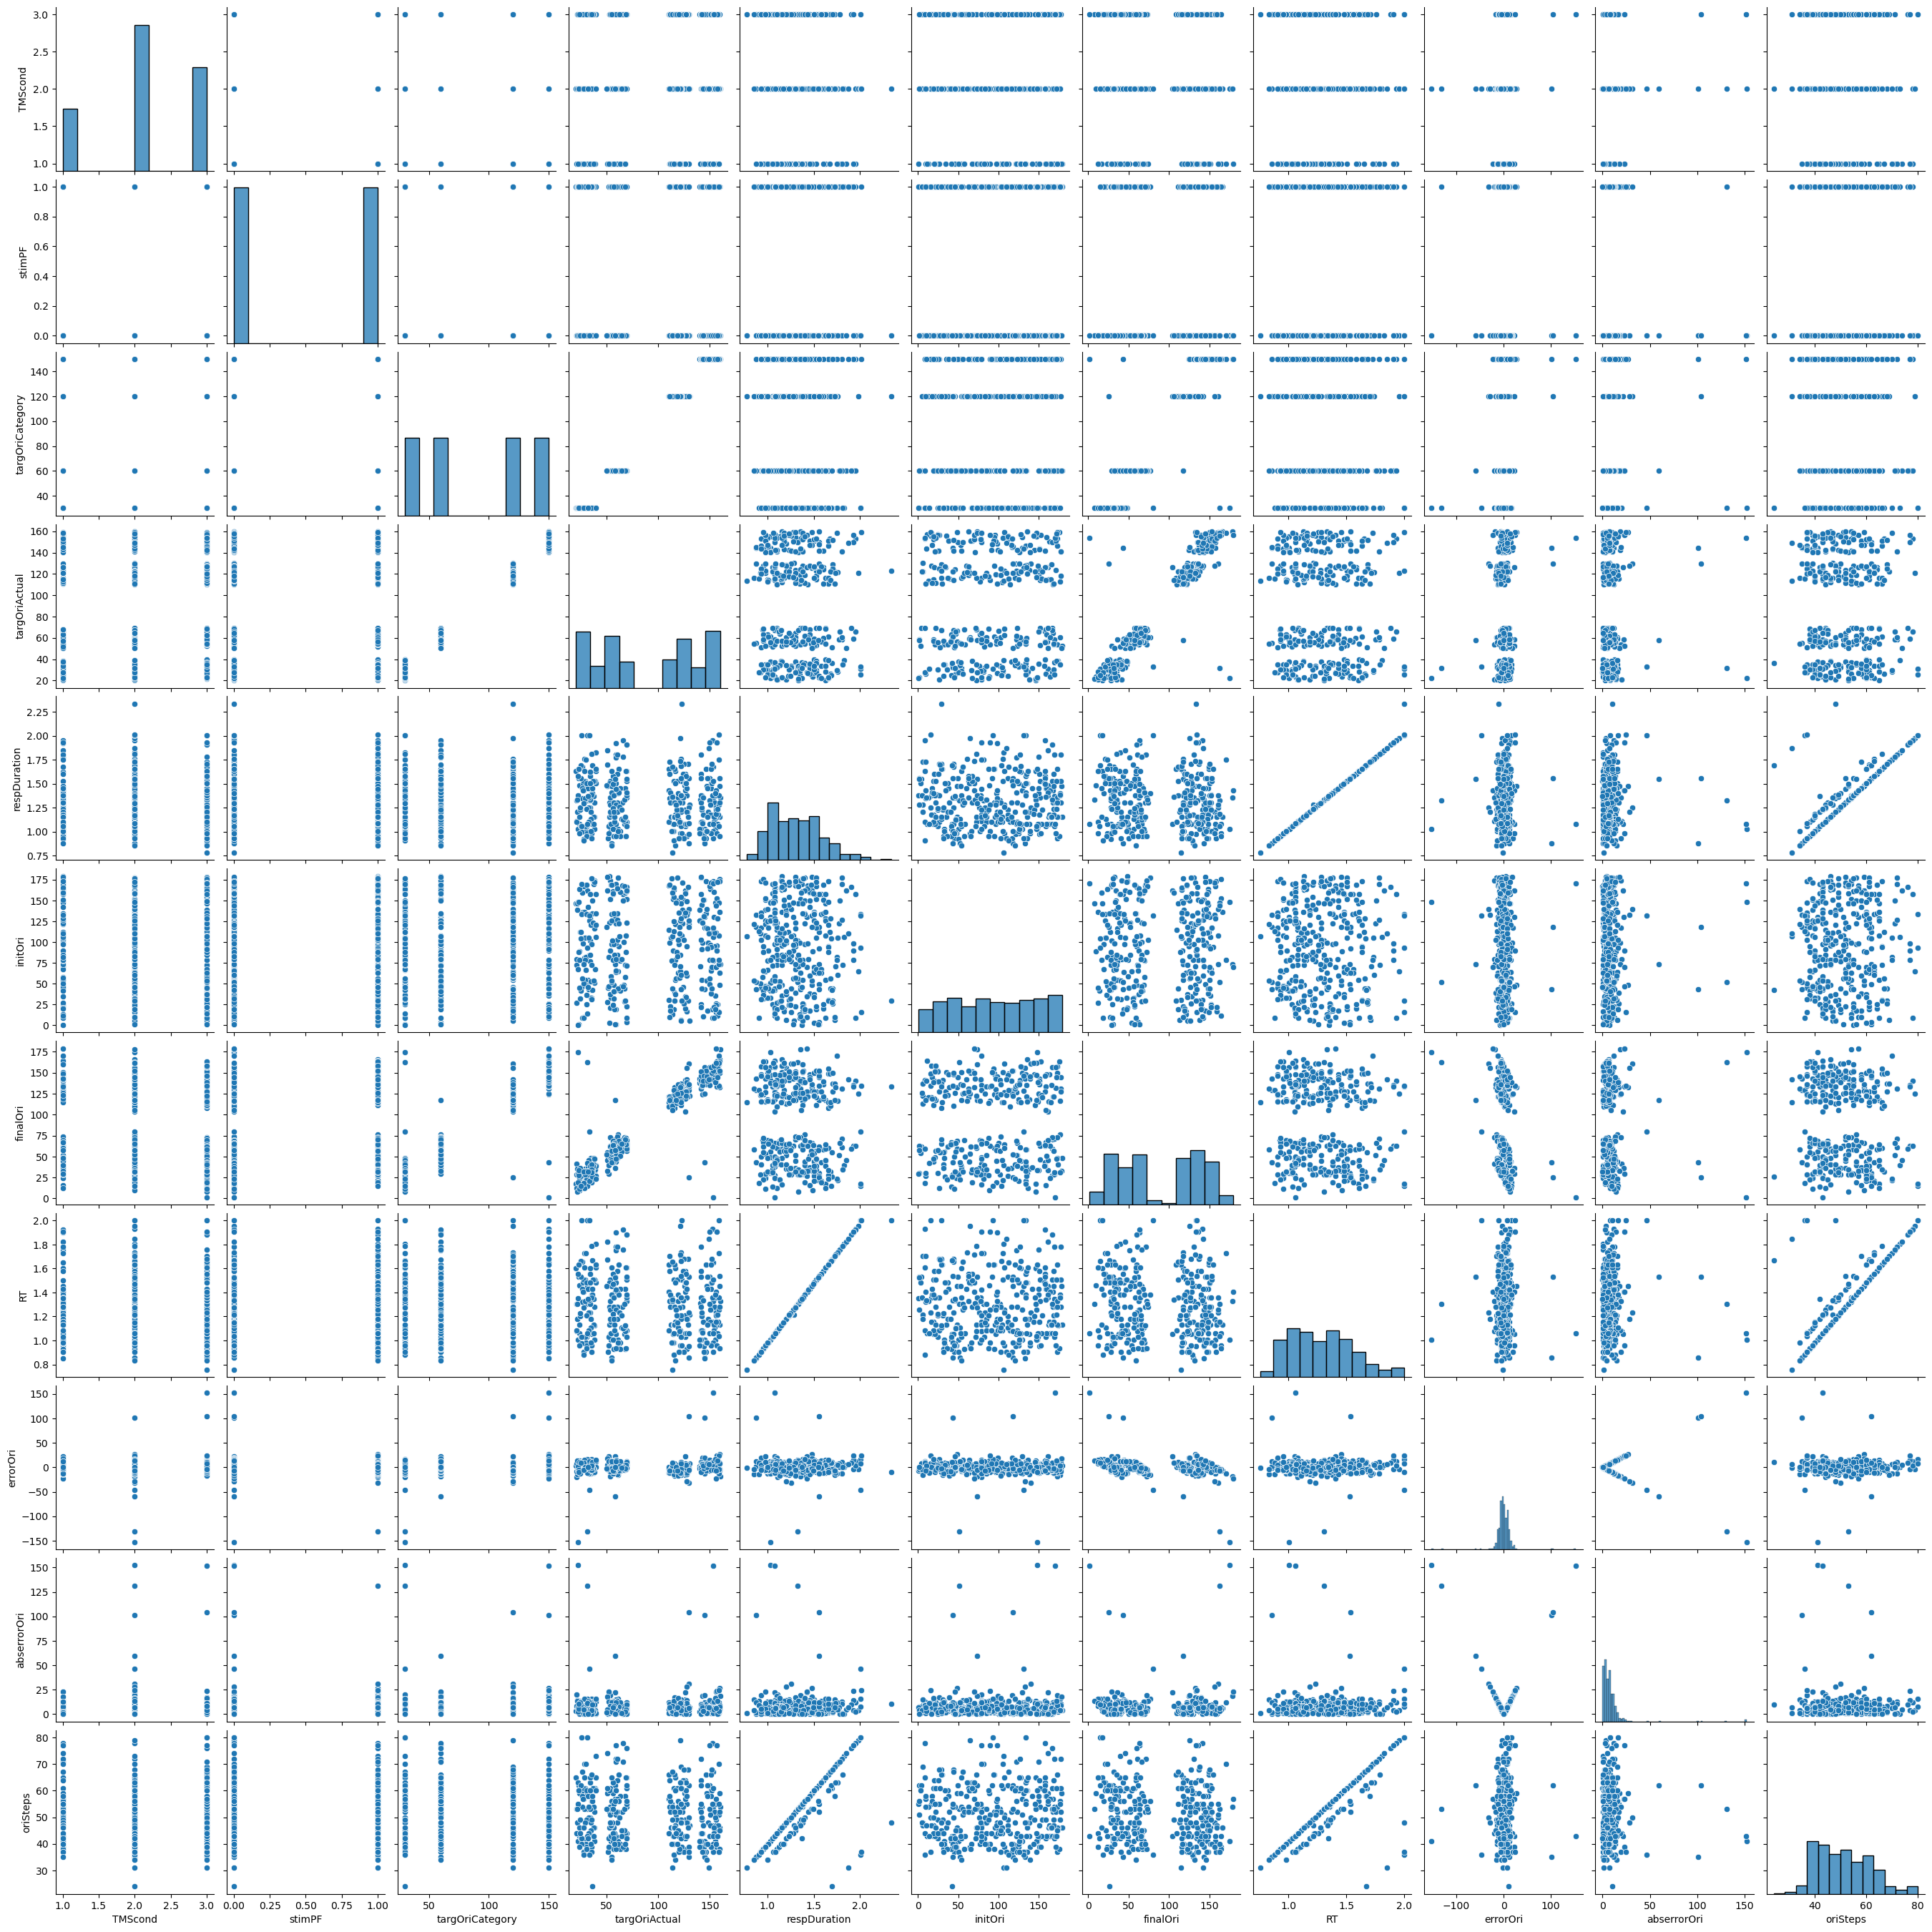

In [5]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()

In [13]:
PF_arr = [0, 1]
targOriCategory_arr = df['targOriCategory'].unique()
RT_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))
error_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))

from itertools import product
for ii, jj in product(range(len(PF_arr)), range(len(targOriCategory_arr))):
    RT_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['RT'].mean()
    error_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['abserrorOri'].mean()

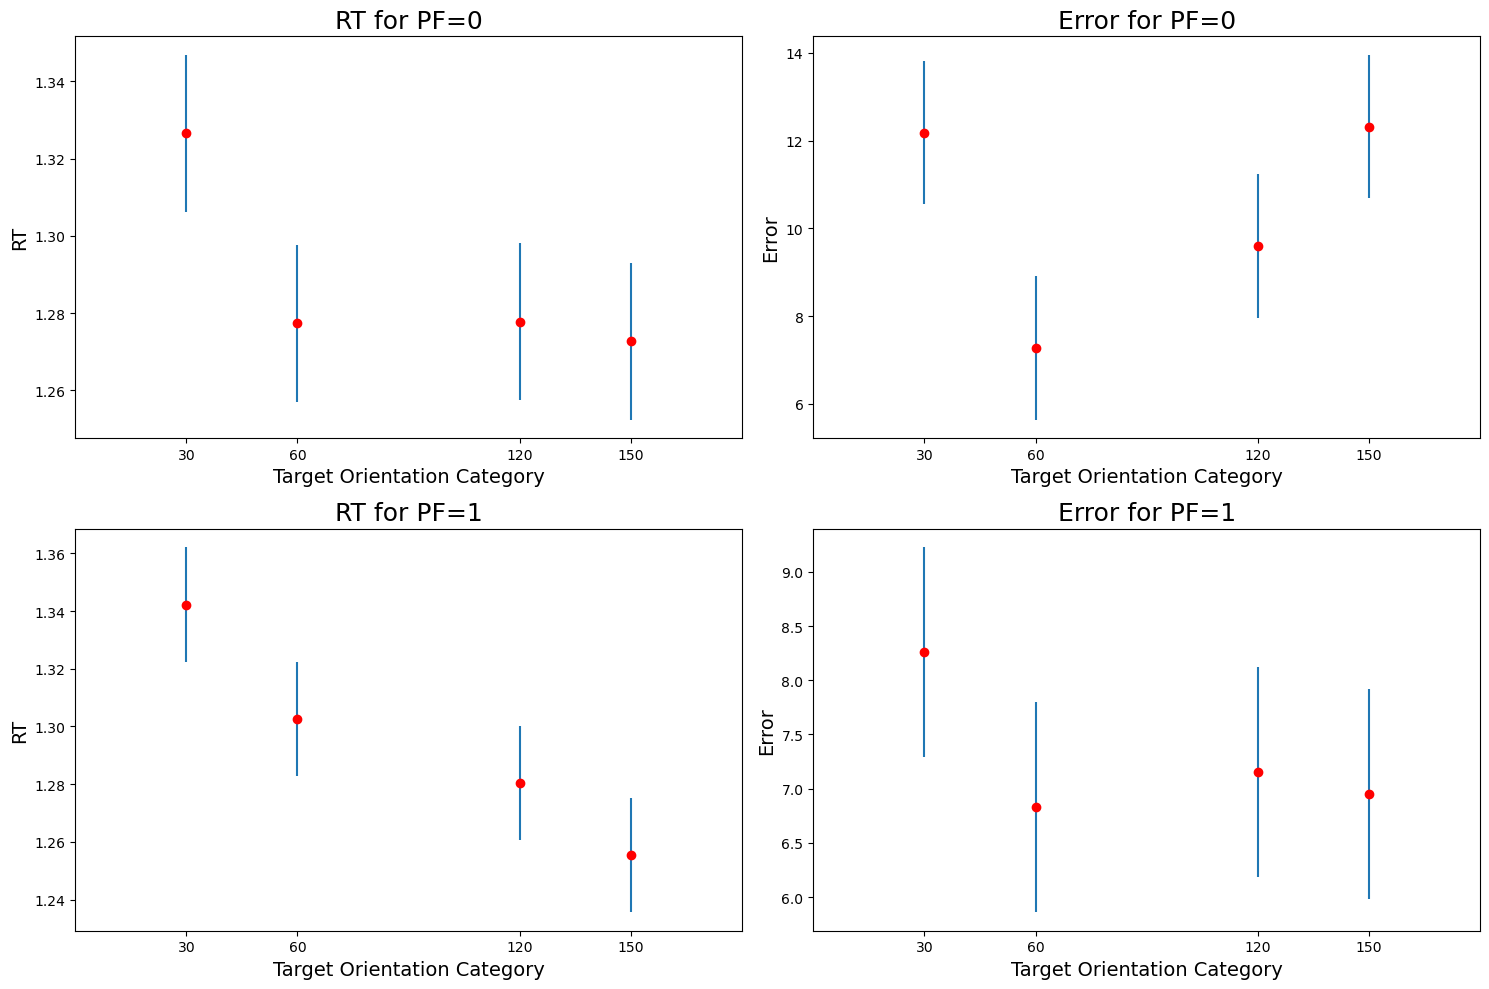

In [17]:
# Plot mean and error for both RT and error for different PF_arr
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for ii in range(len(PF_arr)):
    # ax[ii, 0].bar(targOriCategory_arr, RT_holder[ii, :], label=f'PF={PF_arr[ii]}')
    # ax[ii, 1].bar(targOriCategory_arr, error_holder[ii, :], label=f'PF={PF_arr[ii]}')
    axs[ii, 0].errorbar(targOriCategory_arr, RT_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['RT']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 0].plot(targOriCategory_arr, RT_holder[ii, :], 'ro')
    axs[ii, 0].set_xlim(0, 180)
    axs[ii, 0].set_xticks(targOriCategory_arr)
    axs[ii, 0].set_title(f'RT for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 0].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 0].set_ylabel('RT', fontsize=axes_fontsize)
    axs[ii, 1].errorbar(targOriCategory_arr, error_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['errorOri']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 1].plot(targOriCategory_arr, error_holder[ii, :], 'ro')
    axs[ii, 1].set_xlim(0, 180)
    axs[ii, 1].set_xticks(targOriCategory_arr)
    axs[ii, 1].set_title(f'Error for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 1].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 1].set_ylabel('Error', fontsize=axes_fontsize)
plt.tight_layout()
plt.show()